# Process Discovery Lab
### From Event Log Exploration to Discovery Optimization with PM4Py

**Learning goals**
- Explore event logs and their variant distributions.
- Compare miners on different types of logs.
- Apply top-k and coverage-based variant filtering.
- Implement iterative variant selection.
- Tune Inductive Miner Infrequent.
- Compare model quality and complexity.

## 0. Setup

In [2]:
# If needed, uncomment and run:
!pip install pm4py pandas matplotlib numpy

import random
import itertools
import warnings
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pm4py

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("PM4Py version:", getattr(pm4py, "__version__", "unknown"))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 13.2 MB/s  0:00:00




  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




PM4Py version: 2.7.23.14


## 1. Import event logs



In [4]:
receipt = pm4py.read_xes("/content/receipt.xes")


logs = {'receipt':receipt}


/usr/local/lib/python3.13/dist-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


parsing log, completed traces ::   0%|          | 0/1434 [00:00<?, ?it/s]

## 2. Log exploration

In [5]:
def variant_counts(log):
    variants = pm4py.get_variants(log)

    counts = {
        str(variant): count
        for variant, count in variants.items()
    }

    return pd.Series(counts).sort_values(ascending=False)

def log_summary(log, name="log"):
    variants = variant_counts(log)
    case_col = "case:concept:name"
    activity_col = "concept:name"
    cases = log[case_col].nunique()
    events = len(log)
    activities = log[activity_col].nunique()
    lengths = log.groupby(case_col).size()
    return {
        "log": name,
        "cases": cases,
        "events": events,
        "activities": activities,
        "variants": len(variants),
        "avg_trace_length": lengths.mean(),
        "min_trace_length": lengths.min(),
        "max_trace_length": lengths.max()
    }

summary = pd.DataFrame([log_summary(log, name) for name, log in logs.items()])
summary

,log,cases,events,activities,variants,avg_trace_length,min_trace_length,max_trace_length
0,receipt,1434,8577,27,116,5.981172,1,25


/tmp/ipykernel_846/921048503.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


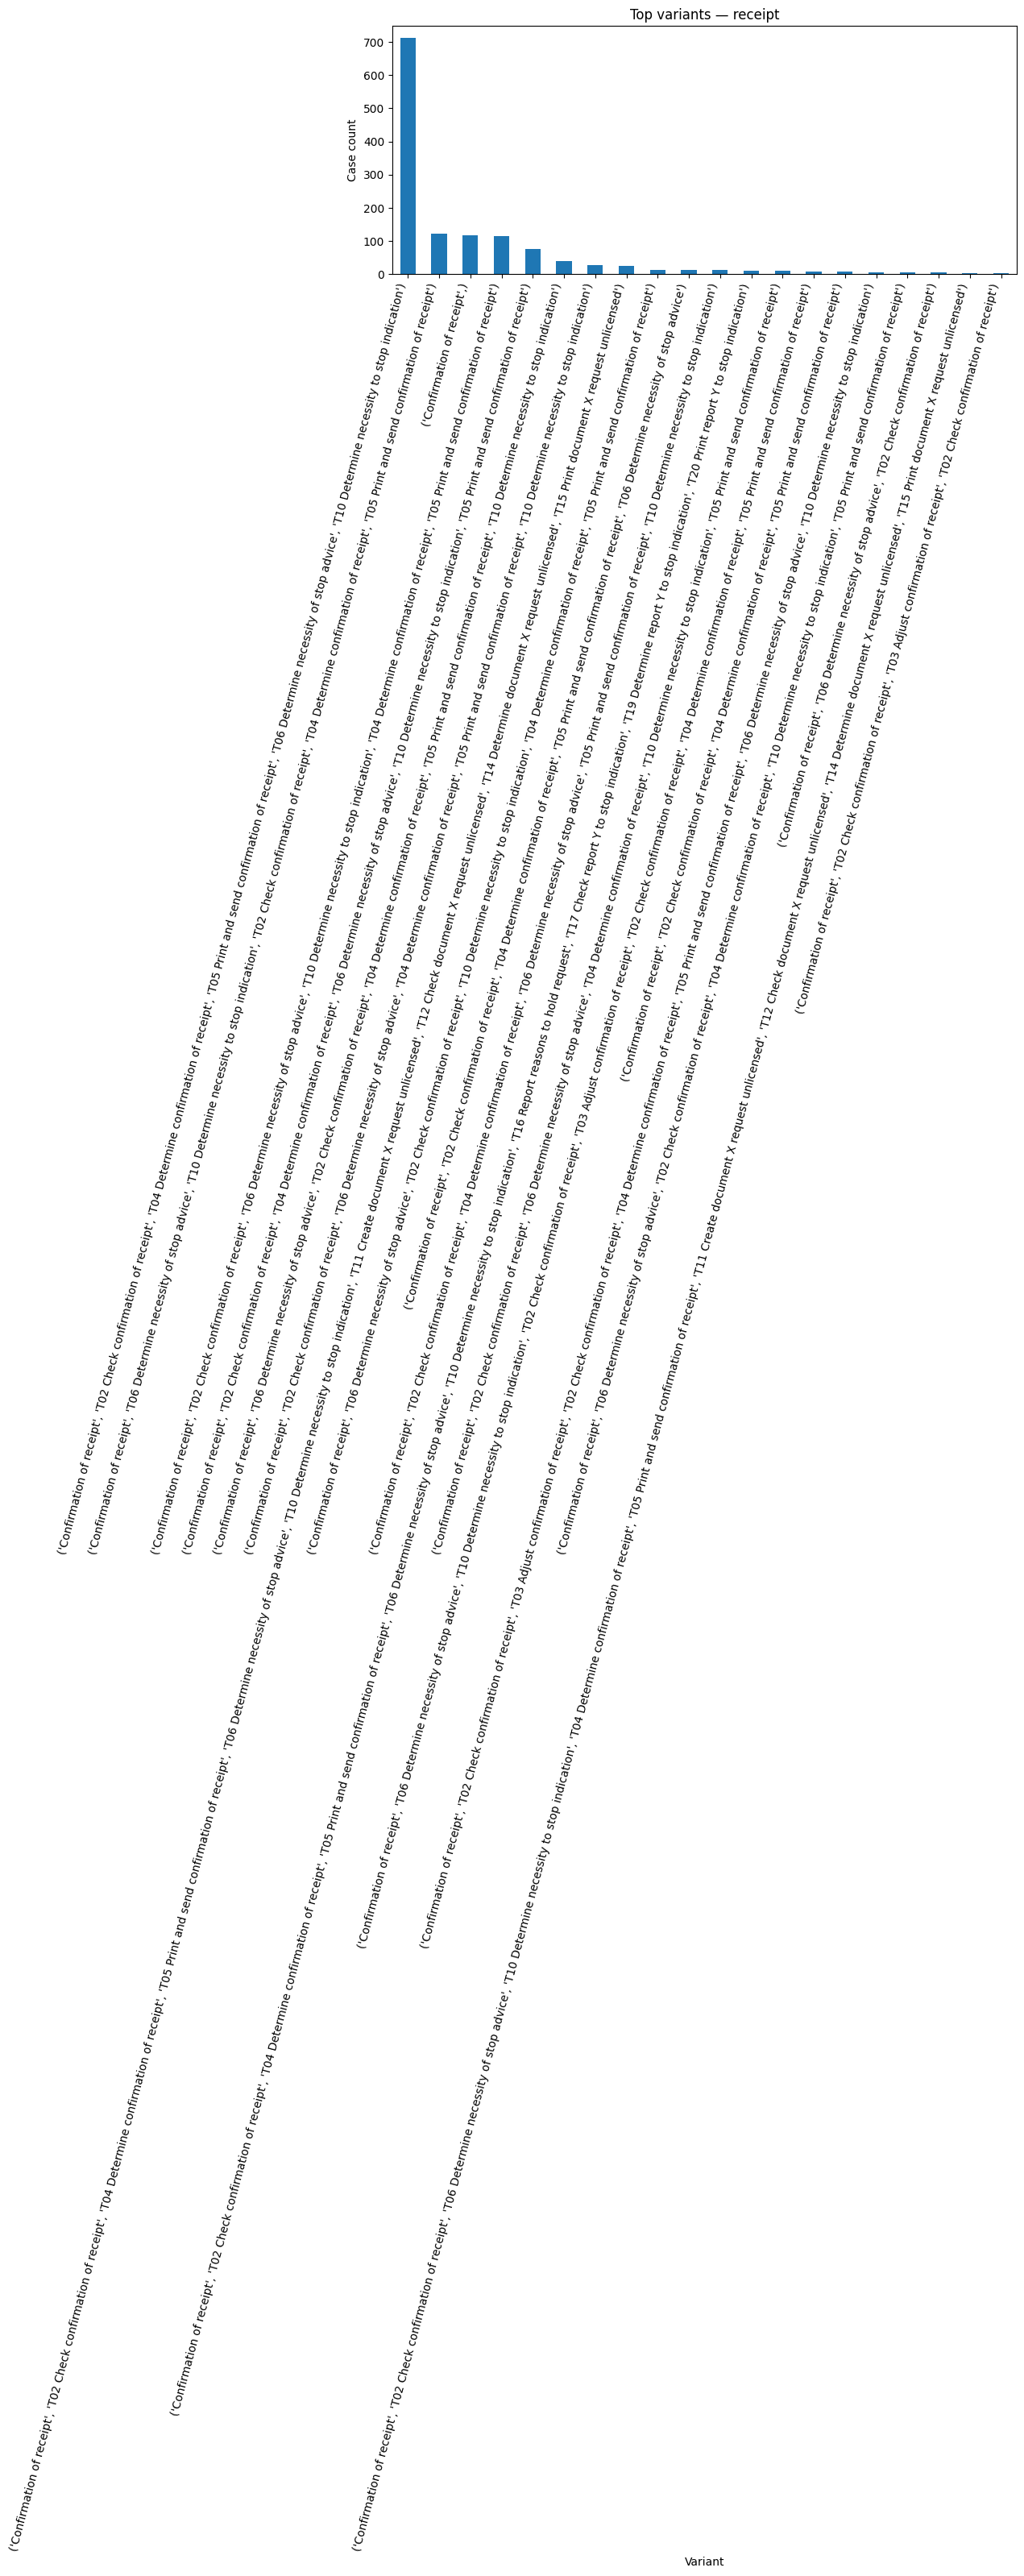

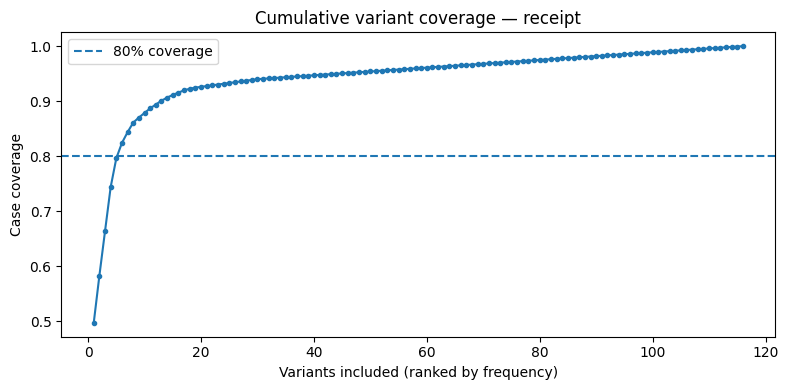

In [6]:
def plot_variant_distribution(log, title):
    counts = variant_counts(log)
    fig, ax = plt.subplots(figsize=(10, 4))
    counts.head(20).plot(kind="bar", ax=ax)
    ax.set_title(f"Top variants — {title}")
    ax.set_xlabel("Variant")
    ax.set_ylabel("Case count")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()

def plot_variant_coverage(log, title):
    counts = variant_counts(log)
    cumulative = counts.cumsum() / counts.sum()
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, len(cumulative)+1), cumulative, marker=".")
    ax.axhline(0.80, linestyle="--", label="80% coverage")
    ax.set_title(f"Cumulative variant coverage — {title}")
    ax.set_xlabel("Variants included (ranked by frequency)")
    ax.set_ylabel("Case coverage")
    ax.legend()
    plt.tight_layout()
    plt.show()

for name, log in logs.items():
    plot_variant_distribution(log, name)
    plot_variant_coverage(log, name)

In [7]:
def variants_needed_for_coverage(log, targets=(0.80, 0.90, 0.95)):
    counts = variant_counts(log)
    cumulative = counts.cumsum() / counts.sum()
    output = {}
    for target in targets:
        idx = np.argmax(cumulative.values >= target)
        output[target] = int(idx + 1)
    return output

coverage_table = pd.DataFrame({
    name: variants_needed_for_coverage(log)
    for name, log in logs.items()
}).T
coverage_table

,0.80,0.90,0.95
receipt,6,13,45


## 3. Preprocessing — Top-k variants

We compare several values of `k`. PM4Py provides a top-k variant filtering function.

In [11]:
def filter_top_k(log, k):
    return pm4py.filter_variants_top_k(log, k)

def retained_case_percentage(original, filtered):
    return 100 * filtered["case:concept:name"].nunique() / original["case:concept:name"].nunique()

def retained_event_percentage(original, filtered):
    return 100 * len(filtered) / len(original)

def retained_k_variants(log):
  k_values = [1, 2, 3, 5, 10, 20]
  topk_results = []

  for k in k_values:
      filtered = filter_top_k(log, k)
      topk_results.append({
          "cases_retained_%": retained_case_percentage(log, filtered),
          "events_retained_%": retained_event_percentage(log, filtered),
          "variants_retained": len(variant_counts(filtered))
      })

  return pd.DataFrame(topk_results)
topk_receipt = retained_k_variants(receipt)
print(topk_receipt)

   cases_retained_%  events_retained_%  variants_retained
0         49.721060          49.877580                  1
1         58.298466          58.481987                  2
2         66.387727          59.834441                  3
3         79.637378          73.125802                  5
4         87.866109          82.546345                 10
5         92.608089          87.886207                 20


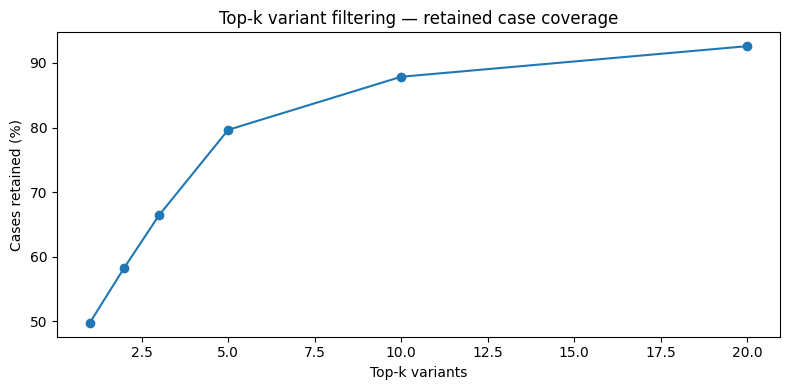

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(topk_receipt["variants_retained"], topk_receipt["cases_retained_%"], marker="o")
ax.set_xlabel("Top-k variants")
ax.set_ylabel("Cases retained (%)")
ax.set_title("Top-k variant filtering — retained case coverage")
plt.tight_layout()
plt.show()

## 4. Preprocessing — Coverage-based filtering

Instead of choosing a number of variants, choose the percentage of cases that should be covered by the selected variants.

In [13]:
def filter_variants_by_cumulative_coverage(log, target):

    case_key = "case:concept:name"
    activity_key = "concept:name"
    timestamp_key = "time:timestamp"

    # Verifica delle colonne
    required = [case_key, activity_key]
    missing = [col for col in required if col not in log.columns]

    if missing:
        raise ValueError(f"Colonne mancanti: {missing}")

    # Ordina gli eventi cronologicamente, se disponibile il timestamp
    ordered_log = log.copy()

    if timestamp_key in ordered_log.columns:
        ordered_log = ordered_log.sort_values(
            timestamp_key, kind="stable"
        )

    # Ricostruisce la sequenza di attività di ciascun caso
    case_variants = (
        ordered_log
        .groupby(case_key, sort=False)[activity_key]
        .agg(tuple)
    )

    # Frequenza di ogni variante
    variant_frequencies = case_variants.value_counts()

    total_cases = len(case_variants)

    # Seleziona le varianti più frequenti fino al target
    selected_variants = set()
    cumulative_cases = 0

    for variant, frequency in variant_frequencies.items():

        selected_variants.add(variant)
        cumulative_cases += frequency

        if cumulative_cases / total_cases >= target:
            break

    # Identifica i case ID da mantenere
    selected_cases = case_variants[
        case_variants.isin(selected_variants)
    ].index

    # Filtra il DataFrame originale
    filtered_log = log[
        log[case_key].isin(selected_cases)
    ].copy()

    return filtered_log

In [14]:
def get_coverage_df(log):

    coverage_targets = [0.70, 0.80, 0.90, 0.95, 0.99]
    coverage_results = []

    case_key = "case:concept:name"
    activity_key = "concept:name"
    timestamp_key = "time:timestamp"

    original_cases = log[case_key].nunique()
    original_events = len(log)

    for target in coverage_targets:

        filtered = filter_variants_by_cumulative_coverage(
            log, target
        )

        retained_cases = filtered[case_key].nunique()
        retained_events = len(filtered)

        # Ricostruisce le varianti del log filtrato
        ordered = filtered.copy()

        if timestamp_key in ordered.columns:
            ordered = ordered.sort_values(
                timestamp_key, kind="stable"
            )

        retained_variants = (
            ordered.groupby(case_key)[activity_key]
            .agg(tuple)
            .nunique()
        )

        coverage_results.append({
            "target_coverage": target,
            "cases_retained_%": round(
                retained_cases / original_cases * 100, 2
            ),
            "events_retained_%": round(
                retained_events / original_events * 100, 2
            ),
            "variants_retained": retained_variants
        })

    return pd.DataFrame(coverage_results)

In [15]:
coverage_receipt = get_coverage_df(receipt)

print("Receipt")
display(coverage_receipt)


Receipt


,target_coverage,cases_retained_%,events_retained_%,variants_retained
0,0.70,74.41,67.88,4
1,0.80,82.43,75.92,6
2,0.90,90.10,85.11,13
3,0.95,95.05,91.42,45
4,0.99,99.02,98.85,102


## 5. Discovery algorithms

We create wrappers for a common set of discovery algorithms. Discovery APIs may vary slightly across PM4Py releases; this section uses the high-level PM4Py functions.

In [16]:
def discover_inductive_petri_net(log, noise_threshold=0.0):
    net, initial_marking, final_marking = pm4py.discover_petri_net_inductive(
        log,
        noise_threshold=noise_threshold
    )
    return net, initial_marking, final_marking

def discover_alpha_net(log):
    return pm4py.discover_petri_net_alpha(log)

def visualize_petri_net(net, initial_marking, final_marking):
    pm4py.view_petri_net(net, initial_marking, final_marking)

### 5.1 Inductive Miner

Discover and visualize a process tree on the clean log.



In [17]:
im_net, im_initial_marking, im_final_marking = discover_inductive_petri_net(receipt, noise_threshold=0.0)
visualize_petri_net(im_net, im_initial_marking, im_final_marking)

### 6.2 Alpha Miner

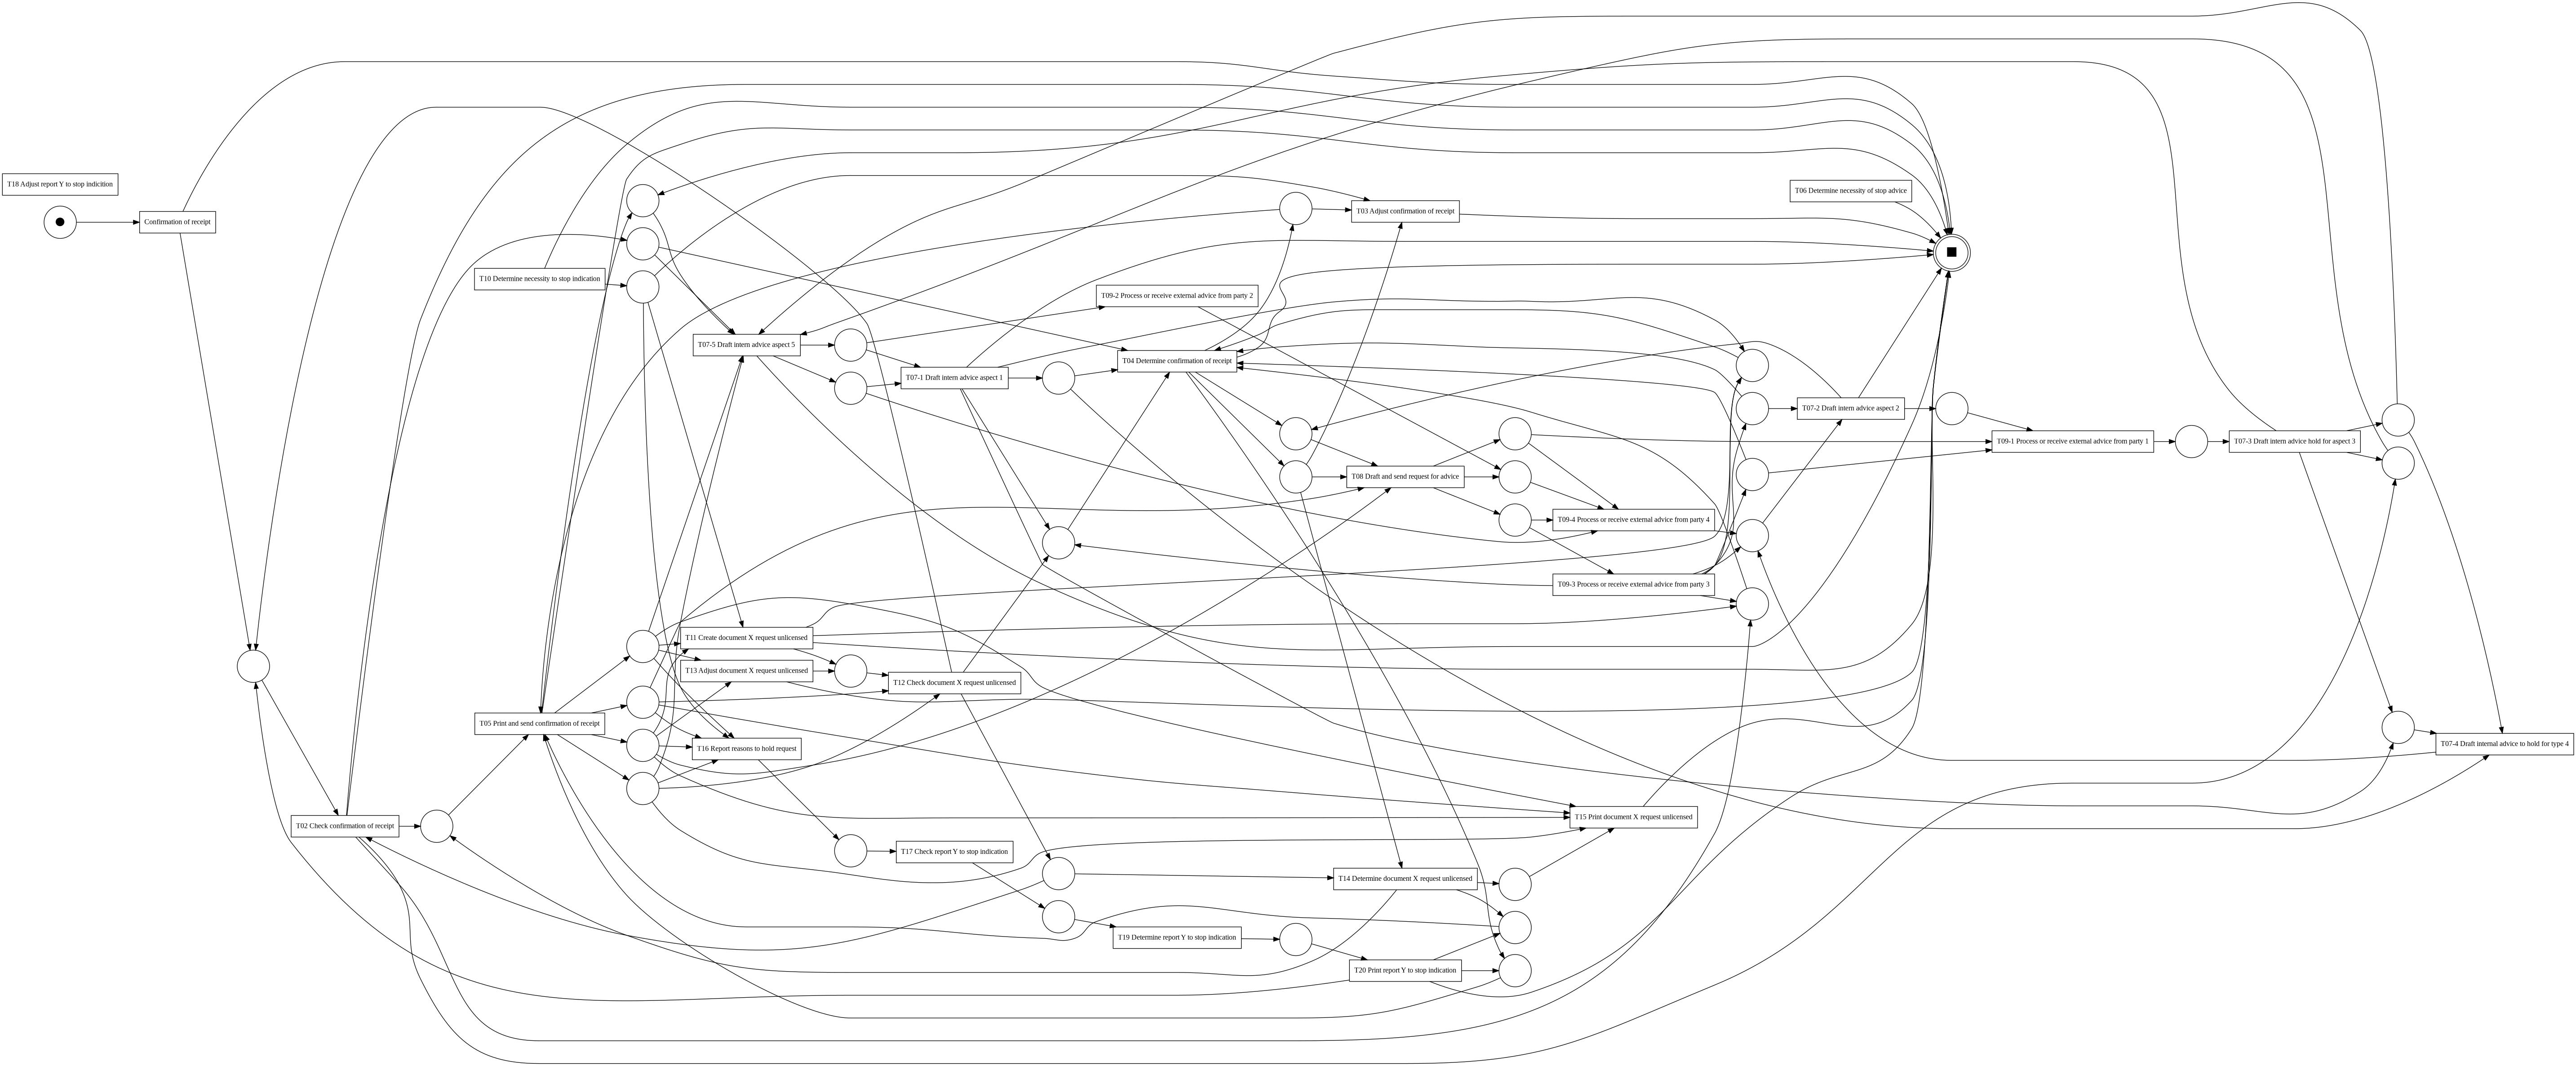

In [18]:
alpha_net, alpha_im, alpha_fm = discover_alpha_net(receipt)
visualize_petri_net(alpha_net, alpha_im, alpha_fm)

## 6. Model complexity indicators

We use basic structural indicators as a simple complexity proxy. These are not a complete measure of model complexity or interpretability.

In [19]:
def petri_net_size(net):
    return {
        "places": len(net.places),
        "transitions": len(net.transitions),
        "arcs": len(net.arcs),
        "visible_transitions": sum(1 for t in net.transitions if t.label is not None),
        "silent_transitions": sum(1 for t in net.transitions if t.label is None)
    }

print(petri_net_size(alpha_net))
print(petri_net_size(im_net))

{'places': 39, 'transitions': 27, 'arcs': 137, 'visible_transitions': 27, 'silent_transitions': 0}
{'places': 45, 'transitions': 74, 'arcs': 158, 'visible_transitions': 27, 'silent_transitions': 47}


## 7. Inductive Miner Infrequent — threshold sweep

We use the Inductive Miner implementation with its `noise_threshold` parameter. The values below are exploratory: the useful range depends on the log. Start with a modest sweep and expand it if needed.

In [21]:
def get_best_imf(log):
  thresholds = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40]
  imf_models = {}
  imf_results = []

  for threshold in thresholds:
      net, im, fm = discover_inductive_petri_net(log, noise_threshold=threshold)
      imf_models[threshold] = (net, im, fm)
      size = petri_net_size(net)
      imf_results.append({
          "threshold": threshold,
          **size
      })

  imf_results_df = pd.DataFrame(imf_results)
  return imf_results_df
receipt_imf_results = get_best_imf(receipt)
print(receipt_imf_results)

   threshold  places  transitions  arcs  visible_transitions  \
0       0.00      45           74   158                   27   
1       0.05      48           67   146                   24   
2       0.10      44           62   134                   27   
3       0.15      43           60   130                   27   
4       0.20      47           69   146                   27   
5       0.30      24           42    84                   25   
6       0.40      37           57   116                   25   

   silent_transitions  
0                  47  
1                  43  
2                  35  
3                  33  
4                  42  
5                  17  
6                  32  


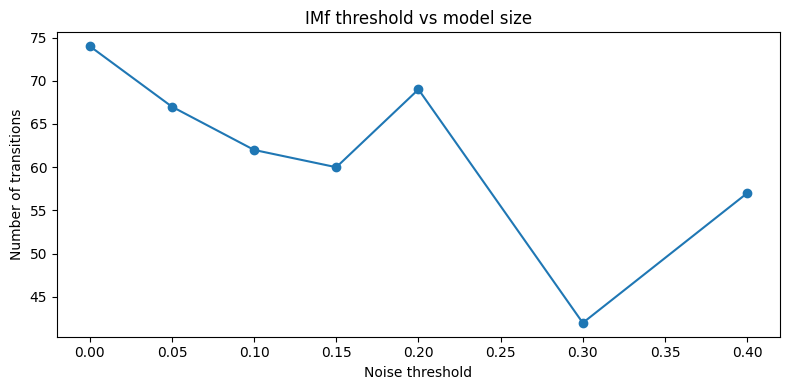

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(receipt_imf_results["threshold"], receipt_imf_results["transitions"], marker="o")
ax.set_xlabel("Noise threshold")
ax.set_ylabel("Number of transitions")
ax.set_title("IMf threshold vs model size")
plt.tight_layout()
plt.show()

## 8. Evaluation — fitness and precision

The evaluation functions can differ across PM4Py versions and depend on the model type. This section provides a small wrapper using alignments replay where supported. If a metric is unavailable in your installed version, inspect the PM4Py evaluation API and adapt the call.

In [24]:
def evaluate_petri_net(log, net, im, fm):
    metrics = {}
    try:
        fit = pm4py.fitness_alignments(log, net, im, fm)
        metrics["fitness"] = fit['averageFitness']
    except Exception as exc:
        metrics["fitness_error"] = str(exc)

    try:
        prec = pm4py.precision_alignments(log, net, im, fm)
        metrics["precision"] = prec
    except Exception as exc:
        metrics["precision_error"] = str(exc)

    try:
        fmeaseure = 2 * (prec * fit['averageFitness']) / (prec + fit['averageFitness'])
        metrics["fmeasure"] = fmeaseure
    except Exception as exc:
        metrics["fmeasure_error"] = str(exc)

    metrics.update(petri_net_size(net))
    return metrics

# Example: evaluate one IMf model against the original noisy log
example_threshold = 0.10
net, im, fm = discover_inductive_petri_net(receipt, noise_threshold=example_threshold)
evaluate_petri_net(receipt, net, im, fm)

aligning log, completed variants ::   0%|          | 0/116 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/458 [00:00<?, ?it/s]

{'fitness': 0.9253865202288648,
 'precision': 0.411945542380325,
 'fmeasure': 0.5701035107815589,
 'places': 44,
 'transitions': 62,
 'arcs': 134,
 'visible_transitions': 27,
 'silent_transitions': 35}

**Important methodological note:** evaluate filtered models against both (a) the filtered training log and (b) the original log. Otherwise, preprocessing can appear to improve quality simply because the evaluation log has also been simplified.

## 9. Experiment runner

A compact runner makes it possible to compare preprocessing strategies systematically.

In [26]:
def get_coverage_df(log, target):
        case_key = "case:concept:name"
        activity_key = "concept:name"
        timestamp_key = "time:timestamp"

        original_cases = log[case_key].nunique()
        original_events = len(log)


        filtered = filter_variants_by_cumulative_coverage(
            log, target
        )

        retained_cases = filtered[case_key].nunique()
        retained_events = len(filtered)

        # Ricostruisce le varianti del log filtrato
        ordered = filtered.copy()

        return ordered

def run_inductive_experiment(log, experiment_name, noise_threshold=0.0):
    net, im, fm = discover_inductive_petri_net(log, noise_threshold=noise_threshold)
    metrics = evaluate_petri_net(log, net, im, fm)
    return {
        "experiment": experiment_name,
        "cases": log["case:concept:name"].nunique(),
        "events": len(log),
        "variants": len(variant_counts(log)),
        "noise_threshold": noise_threshold,
        **metrics
    }

experiment_rows = []

experiment_rows.append(
    run_inductive_experiment(receipt, "Original", 0.0)
)

for k in [3, 5, 10]:
    filtered = filter_top_k(receipt, k)
    experiment_rows.append(
        run_inductive_experiment(filtered, f"Top-{k}", 0.0)
    )

for target in [0.80, 0.90, 0.95]:
    filtered = get_coverage_df(receipt, target)
    experiment_rows.append(
        run_inductive_experiment(filtered, f"Coverage-{target:.0%}", 0.0)
    )

experiment_df = pd.DataFrame(experiment_rows)
experiment_df

aligning log, completed variants ::   0%|          | 0/116 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/458 [00:00<?, ?it/s]

aligning log, completed variants ::   0%|          | 0/3 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/9 [00:00<?, ?it/s]

aligning log, completed variants ::   0%|          | 0/5 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/14 [00:00<?, ?it/s]

... (5 outputs left out)

computing precision with alignments, completed variants ::   0%|          | 0/30 [00:00<?, ?it/s]

aligning log, completed variants ::   0%|          | 0/45 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/147 [00:00<?, ?it/s]

,experiment,cases,events,variants,noise_threshold,fitness,precision,fmeasure,places,transitions,arcs,visible_transitions,silent_transitions
0,Original,1434,8577,116,0.0,1.0,0.166105,0.284888,45,74,158,27,47
1,Top-3,952,5132,3,0.0,1.0,0.567462,0.724052,12,9,24,6,3
2,Top-5,1142,6272,5,0.0,1.0,0.686078,0.813816,12,9,24,6,3
3,Top-10,1260,7080,10,0.0,1.0,0.705692,0.827455,16,14,34,10,4
4,Coverage-80%,1182,6512,6,0.0,1.0,0.688367,0.815423,12,9,24,6,3
5,Coverage-90%,1292,7300,13,0.0,1.0,0.864979,0.927602,17,19,40,14,5
6,Coverage-95%,1363,7841,45,0.0,1.0,0.191189,0.321006,38,58,124,23,35


## 10. Visual comparison of experiment results

Inspect the resulting metrics and discuss the model size versus quality trade-off. Be careful not to treat model size as a direct measure of model quality.

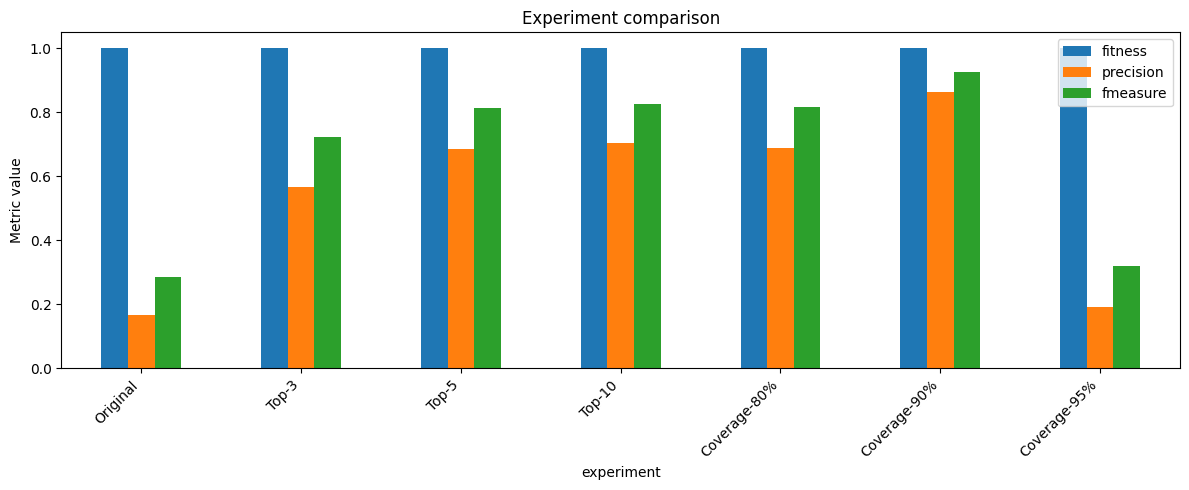

In [27]:
numeric_cols = [
    c for c in ["fitness", "precision", "fmeasure"]
    if c in experiment_df.columns
]

experiment_df[numeric_cols + ["experiment"]].set_index("experiment").plot(
    kind="bar", figsize=(12, 5)
)
plt.title("Experiment comparison")
plt.ylabel("Metric value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 12. Final challenge

### Task
* Implementing iterative strategy based on F-measure improvements with a frequency-based variants approach.

* Implementing iterative strategy based on F-measure improvements with a filter-based mechanism (e.g: Inductive Miner noise threshold) approach.
